---
# 03. Recomendador por contenido (TF-IDF)

> 🟦 **Esta parte es el modelo BASELINE.** Es el punto de partida contra el que se mide todo lo demás.

**La idea en una frase:** si dos recetas usan las mismas palabras (los mismos ingredientes, el mismo tipo de plato), lo más probable es que se parezcan.

```text
recetas_modelo.csv  ->  recipe_text  ->  TF-IDF  ->  una fila de números por receta  ->  comparar  ->  las N más parecidas
```

Este modelo **no sabe nada de personas** (ni favoritos ni historial). Solo compara recetas entre sí.

Esta parte tiene tres etapas:

| Etapa | Secciones | Qué hacemos |
| --- | --- | --- |
| **Construirlo** | 1.1 a 1.9 | Leer los datos, convertir el texto en números y recomendar recetas parecidas |
| **Guardarlo** | 1.10 | Dejar el modelo en archivos para no recalcularlo |
| **Medirlo** | 1.11 | Ponerle calificaciones (métricas) para saber qué tan bueno es |


## 1.1 Librerías

* `pandas`: para leer y manejar la tabla.
* `scikit-learn`: para convertir el texto en números (TF-IDF) y comparar recetas.
* `joblib`: para guardar el modelo en un archivo y no tener que recalcularlo.


In [ ]:
# --- Herramientas básicas de Python ---
# sys: nos deja agregar carpetas al camino donde Python busca módulos (para poder usar `src/`).
import sys
from pathlib import Path

# --- Herramientas de datos y de machine learning ---
# joblib: guarda objetos (como nuestro modelo) en un archivo y luego los vuelve a cargar.
import joblib
import numpy as np
import pandas as pd
# TfidfVectorizer: convierte texto en números usando TF-IDF (se explica en la sección 1.4).
from sklearn.feature_extraction.text import TfidfVectorizer
# cosine_similarity: mide qué tan parecidas son dos filas de números (similitud coseno).
from sklearn.metrics.pairwise import cosine_similarity

# Al mostrar tablas, deja ver hasta 80 caracteres por celda (si no, los textos largos se cortan).
pd.set_option("display.max_colwidth", 80)


## 1.2 Cargar el dataset del modelo

La celda funciona igual si Jupyter arranca en la carpeta del proyecto o dentro de `notebooks/`.

Antes de seguir revisamos tres cosas, para no entrenar con datos rotos:

1. que estén las columnas que vamos a usar;
2. que ninguna receta tenga el texto vacío;
3. que no haya recetas repetidas (`recipe_id` único).


In [2]:
# Paso 1: encontrar la carpeta principal del proyecto (la que contiene la carpeta `data`).
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").exists():      # si estamos dentro de notebooks/, subimos un nivel
    PROJECT_DIR = PROJECT_DIR.parent
sys.path.insert(0, str(PROJECT_DIR))

# Paso 2: ruta del archivo CSV con las recetas ya limpias (lo dejó listo el notebook 02).
DATA_PATH = PROJECT_DIR / "data" / "processed" / "recetas_modelo.csv"
# Leemos el CSV y lo guardamos en `df`: una tabla con una fila por receta.
df = pd.read_csv(DATA_PATH)

# Paso 3: revisiones de seguridad antes de entrenar.
# Lista de columnas que vamos a necesitar más adelante.
COLUMNAS_NECESARIAS = ["recipe_id", "recipe_key", "name", "ingredients_core", "recipe_text",
                       "country", "difficulty", "total_time_min"]
# Buscamos si falta alguna de esas columnas.
faltan = [c for c in COLUMNAS_NECESARIAS if c not in df.columns]
# `assert` detiene el notebook con un mensaje claro si algo está mal. Revisamos 3 cosas:
#   1) que no falten columnas, 2) que ninguna receta tenga el texto vacío,
#   3) que no haya recetas repetidas.
assert not faltan, f"Faltan columnas: {faltan}"
assert df["recipe_text"].notna().all() and (df["recipe_text"].str.strip() != "").all(), "hay textos vacíos"
assert df["recipe_id"].is_unique, "hay recetas repetidas"

# Resumen: de dónde leímos los datos y cuántas recetas y columnas hay.
print("Archivo:", DATA_PATH.relative_to(PROJECT_DIR))
print(f"Recetas: {len(df):,} | columnas: {df.shape[1]}")


Archivo: data/processed/recetas_modelo.csv
Recetas: 28,798 | columnas: 43


## 1.3 ¿Qué lee el modelo?

El modelo lee **una sola columna**: `recipe_text`. El notebook 02 la armó juntando lo que de verdad describe al plato:

```text
recipe_text = nombre + ingredientes base + etiquetas + país
```

Las demás columnas (`is_quick`, `tag_vegetariana`, `difficulty`...) **no entran al modelo**,
pero sirven después para **filtrar** (sección 1.9).


In [3]:
# Primeras 3 recetas: nombre, ingredientes base y el texto final (`recipe_text`) que leerá el modelo.
df[["name", "ingredients_core", "recipe_text"]].head(3)


,name,ingredients_core,recipe_text
0,Mole Negro,muslo de pollo | pierna de pollo | laurel | pimienta gorda | ajo | tomillo |...,mole negro muslo de pollo pierna de pollo laurel pimienta gorda ajo tomillo ...
1,Pizza en Sarten con Harina de Garbanzos,harina de garbanzo | ajo en polvo | cebolla en polvo | cebollin desidratado ...,pizza en sarten con harina de garbanzos harina de garbanzo ajo en polvo cebo...
2,6 Donas de Sabores,agua | levadura | harina | sal | azucar | huevo | mantequilla sin sal | lech...,6 donas de sabores agua levadura harina sal azucar huevo mantequilla sin sal...


## 1.4 TF-IDF: de palabras a números

La computadora no entiende palabras, solo números. TF-IDF le pone a cada palabra un **puntaje** dentro de cada receta:

* **sube** si la palabra aparece en esta receta;
* **baja** si la palabra aparece en muchísimas recetas.

Ejemplo: `chipotle` sale en pocas recetas, así que cuando aparece dice mucho del plato (puntaje alto).
`agua` sale en muchas, así que dice poco (puntaje bajo).

Los ajustes que usamos:

| Ajuste | Qué hace | Por qué |
| --- | --- | --- |
| `ngram_range=(1, 1)` | Mira solo palabras sueltas (`pollo`, `chipotle`) | Ver la nota de abajo |
| `min_df=2` | Ignora palabras que salen en una sola receta | Suelen ser errores de escritura; no ayudan a encontrar parecidas |
| `max_df=0.5` | Ignora palabras que salen en más de la mitad de las recetas | `sal` está en más de la mitad: no sirve para distinguir un plato de otro |
| `sublinear_tf=True` | Si una palabra se repite mucho en la misma receta, no la deja dominar | Evita que una receta "gane" solo por repetir `pollo` cinco veces |
| `lowercase` y `strip_accents` | Todo en minúsculas y sin acentos | El texto de las recetas ya viene así; esto sirve para lo que escriba la persona ("Plátano" = "platano") |

**Nota: ¿por qué solo palabras sueltas y no pares de palabras?**

TF-IDF también puede mirar pares de palabras seguidas (`ngram_range=(1, 2)`), y la primera versión lo hacía.
El problema es que en `recipe_text` los ingredientes van uno tras otro, sin separación:

```text
... tortilla de maiz amarillo lechuga frijol refrito ...
```

Así salían "pares" que mezclan dos ingredientes distintos, como `amarillo lechuga` o `lechuga frijol`.
Esos pares casi nunca se repiten, así que TF-IDF les daba **mucho peso**, y las recomendaciones dependían de ese ruido.

Con palabras sueltas eso desaparece. Lo comprobamos con la evaluación de este notebook (sección 1.11) y la comparación del notebook 05:
con palabras sueltas el modelo acierta más en las dos pruebas (NDCG@10 pasa de 0.415 a 0.492 y de 0.218 a 0.241)
y el modelo queda unas 8 veces más chico.


In [ ]:
# Ajustes de TF-IDF (explicados en la tabla de arriba).
TFIDF_PARAMS = dict(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 1),
    min_df=2,
    max_df=0.5,
    sublinear_tf=True,
)
# Creamos el vectorizador con esos ajustes (todavía no ha aprendido nada).
tfidf = TfidfVectorizer(**TFIDF_PARAMS)

# Aprende el vocabulario y convierte cada receta en una fila de números.
# `fit_transform` hace dos cosas: `fit` (aprende el vocabulario y qué tan rara es cada palabra)
# y `transform` (convierte cada receta en una fila de números).
tfidf_matrix = tfidf.fit_transform(df["recipe_text"])

print(f"Recetas (filas)          : {tfidf_matrix.shape[0]:,}")
print(f"Palabras (columnas)       : {tfidf_matrix.shape[1]:,}")
print(f"Casillas con un número    : {tfidf_matrix.nnz / np.prod(tfidf_matrix.shape):.2%}  (el resto son ceros)")


Recetas (filas)          : 28,798
Palabras (columnas)       : 5,436
Casillas con un número    : 0.32%  (el resto son ceros)


## 1.5 ¿Qué aprendió?

La tabla que sale de TF-IDF es enorme, pero **casi toda está llena de ceros**: cada receta solo usa unas pocas
de todas las palabras posibles. Por eso se guarda en un formato que solo anota las casillas con número.

Para ver que tiene sentido, revisamos dos cosas:

1. que las palabras demasiado comunes (como `sal`) quedaron fuera y las útiles (como `chipotle`) quedaron dentro;
2. cuáles son las palabras que más "pesan" en una receta (la función `palabras_clave`, que usamos en la sección 1.7).


In [ ]:
# Revisión 1: ¿quedaron fuera las palabras demasiado comunes (`sal`) y dentro las útiles (`chipotle`)?
# `tfidf.vocabulary_` es el diccionario de palabras que el modelo aprendió.
for palabra in ["sal", "agua", "chipotle", "condensada", "hornear"]:
    print(f"{palabra!r:20} ¿está en el vocabulario? {palabra in tfidf.vocabulary_}")

# Lista con todas las palabras del vocabulario (en el mismo orden que las columnas de la matriz).
vocabulario = np.array(tfidf.get_feature_names_out())


# Revisión 2: función que muestra las palabras que más pesan en una receta.
def palabras_clave(pos, n=10):
    """Las n palabras con más peso en la receta que está en la posición `pos`."""
    fila = tfidf_matrix[pos].toarray().ravel()
    mejores = fila.argsort()[::-1][:n]
    return pd.Series(fila[mejores].round(3), index=vocabulario[mejores], name="peso")


'sal'                ¿está en el vocabulario? False
'agua'               ¿está en el vocabulario? True
'chipotle'           ¿está en el vocabulario? True
'condensada'         ¿está en el vocabulario? True
'hornear'            ¿está en el vocabulario? True


## 1.6 Comparar recetas: similitud coseno

Cada receta ya es una fila de números. Para saber si dos recetas se parecen usamos la **similitud coseno**:
un número entre 0 y 1.

* **cerca de 1**: usan las mismas palabras importantes (muy parecidas);
* **cerca de 0**: no comparten nada importante.

Para recomendar, comparamos **una** receta contra todas las demás y nos quedamos con las más altas.
Nunca armamos la tabla "todas contra todas": con casi 29 mil recetas serían más de 800 millones de números.

Escribimos dos funciones:

* `recomendar_similares(recipe_id)`: "me gustó esta receta, ¿cuáles se parecen?"
* `recomendar_por_texto(texto)`: "tengo estos ingredientes, ¿qué cocino?"

Las dos aceptan `solo={...}` para quedarse únicamente con recetas que cumplan un filtro (lo usamos en la sección 1.9).


In [ ]:
# Columnas que mostramos en cada recomendación.
COLUMNAS_RESULTADO = ["recipe_id", "name", "country", "difficulty", "total_time_min"]


# Función interna: toma el parecido de una receta contra todas las demás y se queda con las n mejores.
def _top_n(similitudes, n, excluir=None, solo=None):
    """Ordena de más a menos parecida y devuelve las n primeras.

    excluir: posición de una receta que no debe salir (la receta de partida).
    solo   : filtro opcional, por ejemplo {"is_quick": 1, "tag_vegetariana": 1}.
    """
    similitudes = similitudes.copy()
    # Si nos dan la receta de partida, le ponemos -1 para que nunca se recomiende a sí misma.
    if excluir is not None:
        similitudes[excluir] = -1                       # así nunca queda arriba
    # Si hay un filtro (por ejemplo, solo recetas rápidas), marcamos qué recetas lo cumplen.
    if solo:
        cumple = np.ones(len(df), dtype=bool)
        # Por cada condición del filtro, nos quedamos solo con las recetas que la cumplen.
        for columna, valor in solo.items():
            cumple &= (df[columna] == valor).to_numpy()
        # Las que NO cumplen el filtro reciben -1: quedan al fondo y no aparecen en el Top.
        similitudes[~cumple] = -1                     
  
    mejores = np.argsort(-similitudes, kind="stable")[:n]
    resultado = df.iloc[mejores][COLUMNAS_RESULTADO].copy()
    resultado["similitud"] = similitudes[mejores].round(3)
    return resultado.reset_index(drop=True)


# FUNCIÓN 1: "me gustó esta receta, ¿cuáles se parecen?"
def recomendar_similares(recipe_id, n=10, solo=None):
    """Las n recetas más parecidas a una receta del catálogo."""
    # Buscamos en qué fila de la tabla está esa receta.
    posiciones = np.flatnonzero(df["recipe_id"].to_numpy() == recipe_id)
    # Si ese recipe_id no existe, avisamos con un error claro.
    if len(posiciones) == 0:
        raise ValueError(f"No existe recipe_id={recipe_id}")
    pos = posiciones[0]
    # Comparamos esa receta contra TODAS las recetas (una fila contra la matriz completa).
    similitudes = cosine_similarity(tfidf_matrix[pos], tfidf_matrix).ravel()
    # Nos quedamos con las n más parecidas (sin incluir la receta de partida).
    return _top_n(similitudes, n, excluir=pos, solo=solo)


# FUNCIÓN 2: "tengo estos ingredientes, ¿qué cocino?"
def recomendar_por_texto(texto, n=10, solo=None):
    """Las n recetas más parecidas a un texto escrito (por ejemplo, una lista de ingredientes)."""
    # Revisamos que nos hayan dado un texto que no esté vacío.
    if not isinstance(texto, str) or not texto.strip():
        raise ValueError("Escribe al menos una palabra.")
    # Convertimos el texto escrito en números (con el mismo vocabulario que las recetas).
    vector = tfidf.transform([texto])                   # el texto pasa por el MISMO vocabulario
    # Lo comparamos contra todas las recetas.
    similitudes = cosine_similarity(vector, tfidf_matrix).ravel()
    return _top_n(similitudes, n, solo=solo)


## 1.7 Primera prueba: unos tacos mexicanos

Tomamos la primera receta mexicana que tenga "tacos" en el nombre. Primero vemos qué palabras pesan más
en ella y luego le pedimos 10 recetas parecidas.

No es una evaluación formal (eso está en la sección 1.11): solo queremos ver que las sugerencias tienen sentido.


In [7]:
# True para las recetas mexicanas cuyo nombre contiene "taco" o "tacos".
es_tacos = df["name"].str.contains(r"\btacos?\b", case=False) & df["country"].eq("México")
# Nos quedamos con la primera de ellas.
ejemplo = df[es_tacos].iloc[0]
# Su posición (fila) en la tabla.
pos_ejemplo = df.index.get_loc(ejemplo.name)

# Mostramos los datos de la receta de partida...
print("recipe_id  :", ejemplo["recipe_id"])
print("Receta     :", ejemplo["name"])
print("Ingredientes:", ejemplo["ingredients_core"])
# ...y las palabras que más pesan en ella según TF-IDF.
print("\nPalabras con más peso:")
print(palabras_clave(pos_ejemplo).to_string())


recipe_id  : 10
Receta     : Tacos de Cerdo con Salsa Roja
Ingredientes: tortilla de maiz amarillo | lechuga | frijol refrito | pierna de cerdo | tomate rojo | cebolla morada | cilantro | chile chipotle ahumado | limon | aceite neutro | ajo | salsa inglesa | comino en polvo | tomate rojo firme | cebolla roja | aceite de girasol | crema de leche | sal | pimienta

Palabras con más peso:
roja       0.297
firme      0.293
neutro     0.243
cerdo      0.226
refrito    0.224
rojo       0.221
pierna     0.216
tacos      0.208
inglesa    0.203
ahumado    0.192


In [8]:
# Pedimos las 10 recetas más parecidas a los tacos de ejemplo.
recomendar_similares(ejemplo["recipe_id"], n=10)


,recipe_id,name,country,difficulty,total_time_min,similitud
0,32,Burrito de Cerdo con Salsa Roja Ahumada,España,intermedio,45.0,0.484
1,10999,Huevo con Tortilla,México,facil,15.0,0.395
2,6061,Sopitos,México,intermedio,75.0,0.387
3,6362,Tacos de Filete con Tocino,México,facil,20.0,0.386
4,7964,Tacos de Camaron y Pulpo,México,intermedio,45.0,0.386
5,10176,Chorizo con Huevo en Salsa Roja,México,facil,30.0,0.381
6,8709,Chicharron en Salsa Roja,México,facil,40.0,0.378
7,1370,Chuletas de Cerdo en Salsa de Chipotle,México,facil,30.0,0.378
8,5950,Tacos Ahogados de Pollo con Salsa Roja,México,facil,35.0,0.373
9,7637,Tacos para Crudos Fresas,México,intermedio,90.0,0.373


**Cómo leer la tabla:** la columna `similitud` dice qué tanto se parece cada receta a la de partida (1 = idéntica).

Ojo: **"se parece en el texto" no es lo mismo que "le va a gustar a esta persona"**.
Este modelo solo compara ingredientes y nombres. Para gustos personales hará falta guardar favoritos (base de datos).


## 1.8 Buscar con lo que tengo

La misma idea sirve cuando la persona **escribe** ingredientes en vez de elegir una receta.
El texto pasa por el mismo TF-IDF y se compara contra todas las recetas.


In [9]:
# Búsqueda por ingredientes: la persona escribe lo que tiene y pedimos 8 recetas.
recomendar_por_texto("pollo jitomate chile", n=8)


,recipe_id,name,country,difficulty,total_time_min,similitud
0,15029,Pollo con Chipotle,México,facil,30.0,0.569
1,12236,Pollo en Salsa de Jitomate,México,facil,25.0,0.557
2,6965,Pollo en Salsa de Chile Guajillo,México,facil,70.0,0.550
3,10889,Salsa de Tomate Verde con Jitomate,México,facil,20.0,0.527
4,6331,Salsa Roja,México,facil,35.0,0.524
5,13908,Pollo con Salsa de Ajonjolí,México,facil,120.0,0.518
6,9611,Pollo en Estofado en Jitomate,México,facil,60.0,0.510
7,9177,Chiles Rellenos de Pollo en Salsa de Tomate,México,facil,30.0,0.508


In [10]:
# Otra búsqueda, ahora de postres.
recomendar_por_texto("chocolate fresa crema", n=8)


,recipe_id,name,country,difficulty,total_time_min,similitud
0,10518,Malteada de Chocolate con Fresa,México,facil,15.0,0.645
1,26953,Bombones Rellenos de Fresa,España,NaN,NaN,0.642
2,12134,Flan de Fresa y Mousse de Chocolate,México,facil,125.0,0.583
3,26335,Tarta de Chocolate Blanco y Fresas,España,NaN,NaN,0.581
4,17907,Fresas con Chocolate,México,facil,30.0,0.577
5,20247,Fudge de Fresa,Internacional,intermedio,90.0,0.557
6,441,Chocoflan de Fresa,México,intermedio,45.0,0.547
7,2051,Cheesecake de Galletas de Chocolate Rellenas con Fresas,Internacional,facil,90.0,0.533


## 1.9 Recomendar + filtrar

Aquí se ve para qué sirven las columnas del dataset que **no** entran al modelo.
El modelo ordena por parecido y después nos quedamos solo con las que cumplen lo que pide la persona:

| Lo que pide la persona | Columna que se usa |
| --- | --- |
| "Algo rápido" | `is_quick == 1` (30 minutos o menos, solo con tiempos reales) |
| "Soy vegetariana" | `tag_vegetariana == 1` |
| "Sin picante" | `is_spicy == 0` |
| "No tengo horno" | `needs_oven == 0` |


In [11]:
# Misma idea, pero SOLO con recetas rápidas (is_quick = 1) y vegetarianas (tag_vegetariana = 1).
recomendar_por_texto("pasta jitomate queso", n=8, solo={"is_quick": 1, "tag_vegetariana": 1})


,recipe_id,name,country,difficulty,total_time_min,similitud
0,14316,Pasta con Queso Crema,México,facil,30.0,0.527
1,14395,Pasta con Espinaca y Jitomate,México,facil,30.0,0.468
2,9378,Linguini con Salsa de Jitomate y Champiñones,México,facil,30.0,0.418
3,7768,Pasta con Jitomate Deshidratado y Alcachofas,México,facil,30.0,0.407
4,14262,Ensalada de Jitomate y Queso Panela,México,facil,15.0,0.401
5,10868,Pasta Fusilli con Queso Ricotta o Requeson,México,intermedio,30.0,0.400
6,17410,Pasta para Ninos con Calabacin y Queso,España,facil,15.0,0.395
7,15478,Salsa de Jitomate,México,facil,30.0,0.395


## 1.10 Guardar el modelo

Guardamos dos archivos para no recalcular TF-IDF cada vez:

* el **vectorizador**: sabe convertir cualquier texto en números con el mismo vocabulario;
* la **matriz**: los números de cada receta, en el mismo orden que el CSV.

Se guarda en `models/recetas_modelo/`, que es la carpeta que lee la app (`src/config.py`).

Al final volvemos a cargar los archivos con la misma función que usa el backend y comprobamos que coinciden con el CSV.
La variable `guardado` que sale de aquí la usamos en la sección 1.11 para medir el baseline **tal como lo carga la app**.


In [12]:
# Funciones del proyecto: `load_artifacts` carga el modelo guardado (igual que lo hace la app)
# y `validate_alignment` comprueba que coincida con el CSV.
from src.models import load_artifacts, validate_alignment

# Carpeta donde guardamos el modelo (la misma que usa la app).
MODELS_DIR = PROJECT_DIR / "models" / "recetas_modelo"
# La creamos si no existe.
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Guardamos el vectorizador (sabe convertir texto nuevo en números)...
joblib.dump(tfidf, MODELS_DIR / "tfidf_vectorizer.joblib")
# ...y la matriz (los números de cada receta, en el mismo orden que el CSV).
joblib.dump(tfidf_matrix, MODELS_DIR / "recipe_tfidf_matrix.joblib")

# Comprobación: se leen de vuelta y coinciden con el recipe_text del CSV.
guardado = load_artifacts(MODELS_DIR)
# Si algo no coincide con el CSV, esta línea lanza un error.
validate_alignment(guardado, df["recipe_text"].tolist())
# Mostramos dónde quedó el modelo y cuánto pesa cada archivo.
print("Guardado y comprobado en:", MODELS_DIR.relative_to(PROJECT_DIR))
# Recorremos los archivos .joblib de la carpeta y mostramos su tamaño en MB.
for archivo in sorted(MODELS_DIR.glob("*.joblib")):
    print(f"  {archivo.name:30} {archivo.stat().st_size / 1e6:5.1f} MB")


Guardado y comprobado en: models/recetas_modelo
  recipe_tfidf_matrix.joblib       6.1 MB
  tfidf_vectorizer.joblib          0.1 MB


## 1.11 Métricas del baseline: ¿qué tan bueno es?

Ya construimos el baseline. En esta sección le ponemos **calificaciones (métricas)**, que sirven para dos cosas:

1. saber **qué tan bueno es el baseline por sí solo**;
2. tener **la nota que el notebook 04 tiene que superar**.

### 1.11.1 ¿Cómo calificamos?

**El problema.** Para decir "este modelo recomienda bien" necesitamos saber **qué recetas son una buena respuesta**
para cada pregunta. No tenemos clics ni calificaciones de personas, así que hay que inventar una regla razonable.

**La regla: "mismo tipo de plato".**

> Una recomendación **cuenta como acierto** si es del **mismo tipo de plato** que la receta de partida
> (tacos con tacos, sopa con sopa, galletas con galletas...).

* El tipo de plato se saca del **nombre**, con 32 tipos definidos en `src/evaluation.py`.
  Solo se miran las **primeras 4 palabras** del nombre, para que "Pollo con ensalada" no cuente como ensalada.
* Palabras que sirven para dulce y salado ("pastel", "helado") piden además que la receta sea postre o bebida.
* Solo entran tipos con **20 recetas o más**, y de cada tipo se eligen **10 recetas al azar** (siempre las mismas).
  Así ningún tipo pesa más que otro. Resultado: **320 preguntas** (32 tipos × 10).
* Todo se guarda en `data/evaluation/recetas_modelo/eval_set.json` para usar **exactamente lo mismo** con el baseline y con los embeddings.

**Dos pruebas distintas.** Hay una trampa: el tipo de plato sale del **nombre**, y el nombre también está en `recipe_text`.
Eso ayuda a TF-IDF, que encuentra recetas que repiten la palabra "tacos". Por eso hacemos dos pruebas:

| | Prueba A — receta completa | Prueba B — solo ingredientes |
| --- | --- | --- |
| Pregunta | "Me gustó esta receta, ¿qué más hay parecido?" | "Tengo estos ingredientes, ¿qué cocino?" |
| Lo que recibe el modelo | La receta entera (con su nombre) | Solo la lista de ingredientes (**sin nombre**) |
| Se parece a la función | `recomendar_similares` | `recomendar_por_texto` |
| ¿Tiene trampa? | Sí: el nombre ayuda | Casi no |

**Lo que esta regla NO mide.**

* "Mismo tipo de plato" no es "le va a gustar a esta persona".
* Unas flautas para unos tacos son buena sugerencia, pero aquí **no cuentan** como acierto.
  Esto baja la nota de **todos** los modelos por igual; por eso comparamos también contra recomendar **al azar**.

### 1.11.2 Preparar herramientas y datos para evaluar

Necesitamos dos herramientas nuevas (`evaluation` para calificar y `matplotlib` para las gráficas) y preparar tres cosas a partir del mismo CSV:

* `texts`: el `recipe_text` de cada receta (lo que leen los modelos);
* `ingredients_text`: solo los ingredientes, separados por comas (como los escribiría una persona). Se usa en la **Prueba B**;
* `app_category`: si la receta es `postre`, `bebida` o `comida`, sacado de las etiquetas.
  Sirve para no confundir, por ejemplo, un "pastel" dulce con un "pastel de carne".


In [ ]:
# --- Herramientas para medir (evaluar) el modelo ---
import matplotlib.pyplot as plt          
from IPython.display import display      
from src import evaluation as ev         # código del proyecto: crea las preguntas de prueba y calcula las métricas

# --- Carpetas donde guardamos las preguntas de prueba, los resultados y las gráficas ---
EVAL_DIR = PROJECT_DIR / "data" / "evaluation" / "recetas_modelo"    # preguntas de prueba y resultados
EVAL_SET_PATH = EVAL_DIR / "eval_set.json"                           # archivo con las preguntas de prueba
FIGURES_DIR = PROJECT_DIR / "notebooks" / "figures"                  # gráficas
EVAL_DIR.mkdir(parents=True, exist_ok=True)                          # crea las carpetas si no existen
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:
# Volvemos a leer el CSV (ya lo habíamos leído en 1.2; se repite para que esta sección se entienda sola,
# la tabla es la misma).
df = pd.read_csv(DATA_PATH)
assert df["recipe_id"].is_unique, "recipe_id debe ser único"
assert df["recipe_text"].notna().all() and (df["recipe_text"].str.strip() != "").all()

texts = df["recipe_text"].astype(str).tolist()
recipe_ids = df["recipe_id"].to_numpy()
id_to_pos = {int(r): i for i, r in enumerate(recipe_ids)}   # de recipe_id a su fila en la tabla

# `ingredients_text`: solo los ingredientes, separados por comas (como los escribiría una persona).
# Se usa en la Prueba B.
ingredients_text = df["ingredients_core"].str.replace(" | ", ", ", regex=False)
# `app_category`: marca cada receta como postre, bebida o comida según sus etiquetas.
# np.select revisa las condiciones en orden: si es postre -> "postre"; si no, si es bebida
# -> "bebida"; y si no es ninguna -> "comida".
df["app_category"] = np.select(
    [df["tag_postre"].eq(1), df["tag_bebida"].eq(1)], ["postre", "bebida"], default="comida"
)

print(f"Recetas: {len(df):,}")
print("\nEjemplo de recipe_text:\n ", texts[5][:300])
print("\nEjemplo de ingredients_text:\n ", ingredients_text.iloc[5][:300])
print("\nTipo de receta:", df["app_category"].value_counts().to_dict())


Recetas: 28,798

Ejemplo de recipe_text:
  hallacas venezolanas carne cochino vino papelon alcaparra harina de maiz aceite de onoto cebolla ajoporro cebollin pimenton rojo pimenton verde aji dulce vinagre pastilla de caldo condimento aceite semilla de onoto harina de maiz precocida agua pimenton cortado en tirita aceituna rellena cebolla en 

Ejemplo de ingredients_text:
  carne, cochino, vino, papelon, alcaparra, harina de maiz, aceite de onoto, cebolla, ajoporro, cebollin, pimenton rojo, pimenton verde, aji dulce, vinagre, pastilla de caldo, condimento, aceite, semilla de onoto, harina de maiz precocida, agua, pimenton cortado en tirita, aceituna rellena, cebolla en

Tipo de receta: {'comida': 22236, 'postre': 5393, 'bebida': 1169}


### 1.11.3 Las preguntas de prueba

Se crean una sola vez y se guardan. Si el archivo ya existe y corresponde a este dataset, se **carga** (así el baseline y los embeddings
siempre se califican con las mismas preguntas). Después medimos cuántas listas de ingredientes de la Prueba B todavía "dicen" el tipo de plato
(por ejemplo, "tortilla para tacos") y calculamos qué nota sacaría alguien que recomienda **al azar**: esa es la referencia mínima.


In [15]:
# Si ya hay un conjunto de preguntas guardado, lo cargamos (así los dos modelos usan siempre las mismas).
if EVAL_SET_PATH.exists():
    eval_set = ev.load_eval_set(EVAL_SET_PATH)
    # Si fue creado con otra versión del dataset, ya no sirve: lo volvemos a crear.
    if eval_set.dataset_rows != len(df):
        print("El conjunto guardado es de otra versión del dataset: se vuelve a crear.")
        eval_set = None
else:
    eval_set = None

# Si no hay conjunto (o no sirve), lo creamos y lo guardamos.
if eval_set is None:
    eval_set = ev.build_eval_set(df)
    ev.save_eval_set(eval_set, EVAL_SET_PATH)
    print("Conjunto de evaluación CREADO en", EVAL_SET_PATH.relative_to(PROJECT_DIR))
else:
    print("Conjunto de evaluación CARGADO desde", EVAL_SET_PATH.relative_to(PROJECT_DIR))

# Revisamos que todas las preguntas existan en el dataset.
assert all(rid in id_to_pos for rid, _ in eval_set.queries)
N_QUERIES = len(eval_set.queries)
print(f"Preguntas: {N_QUERIES} | tipos de plato: {len(eval_set.groups)} | preguntas por tipo: {eval_set.queries_per_group}")

# Tabla con cuántas recetas tiene cada tipo de plato.
resumen_tipos = (
    pd.DataFrame({"tipo de plato": list(eval_set.groups),
                  "recetas de ese tipo": [len(v) for v in eval_set.groups.values()]})
    .sort_values("recetas de ese tipo", ascending=False)
    .reset_index(drop=True)
)
display(resumen_tipos)


Conjunto de evaluación CARGADO desde data/evaluation/recetas_modelo/eval_set.json
Preguntas: 320 | tipos de plato: 32 | preguntas por tipo: 10


,tipo de plato,recetas de ese tipo
0,pasta,1277
1,ensalada,1240
2,pastel_tarta,1146
3,sopa_caldo,866
4,dip_salsa,698
5,empanadas,312
6,galletas,307
7,helado,279
8,pizza,278
9,gelatina,260


In [16]:
# Prueba B: ¿cuántas listas de ingredientes todavía "dicen" el tipo de plato? (por ejemplo, "tortilla para tacos")
# Para cada pregunta: ¿el texto de sus ingredientes contiene el nombre del tipo de plato
# (por ejemplo, "tortilla para tacos")? Guarda True o False.
leak = [
    bool(ev.family_pattern(group).search(ev.normalize_text(ingredients_text.iloc[id_to_pos[rid]])))
    for rid, group in eval_set.queries
]
# El promedio de una lista de True/False es el porcentaje de True.
print(f"Prueba B: {np.mean(leak):.1%} de las listas de ingredientes menciona su tipo de plato "
      f"(en la prueba A, el 100 % lo trae en el nombre).")

# Referencia: qué calificación sacaría alguien que recomienda al azar
# `ev.random_baseline` calcula qué nota sacaría recomendar recetas totalmente al azar.
RANDOM_BASELINE = ev.random_baseline(eval_set, len(df))
print("\nCalificación esperada al azar:", {k: round(v, 4) for k, v in RANDOM_BASELINE.items()})


Prueba B: 13.8% de las listas de ingredientes menciona su tipo de plato (en la prueba A, el 100 % lo trae en el nombre).

Calificación esperada al azar: {'Precision@5': 0.0105, 'Recall@5': 0.0002, 'HitRate@5': 0.0502, 'NDCG@5': 0.0105, 'Precision@10': 0.0105, 'Recall@10': 0.0003, 'HitRate@10': 0.0951, 'NDCG@10': 0.0105}


### 1.11.4 Las calificaciones (métricas)

Para cada pregunta, el modelo devuelve sus 10 recetas favoritas y las calificamos así (con K = 5 y K = 10):

| Métrica | Pregunta que responde | Ejemplo con K = 10 |
| --- | --- | --- |
| **Precision@K** | De las K que recomendó, ¿cuántas son acierto? | 6 aciertos de 10 = 0.6 |
| **HitRate@K** | ¿Hubo **al menos un** acierto entre las K? | sí = 1, no = 0 |
| **NDCG@K** | ¿Los aciertos quedaron **arriba** de la lista? | acertar en el puesto 1 vale más que en el 10 |
| **Recall@K** | De **todas** las recetas que eran acierto, ¿cuántas encontró? | Sale chico siempre, porque hay cientos de aciertos posibles y solo mostramos 10 |

Al final se promedian todas las preguntas. **Más alto = mejor** en todas.

### 1.11.5 Calificar al baseline

Para calificar, cada prueba necesita una función que, dada una pregunta, devuelva el **parecido contra todas las recetas**.
Usamos el modelo `guardado` (el que cargamos en 1.10, tal como lo carga la app). La función `ev.evaluate` se encarga de
sacar el Top-10 de cada pregunta (sin contar la receta de partida) y calcular las ocho métricas.


In [17]:
# Orden en que mostramos las métricas y nombre de cada prueba
ORDER = ["Precision@5", "Precision@10", "Recall@5", "Recall@10", "HitRate@5", "HitRate@10", "NDCG@5", "NDCG@10"]
PROTOCOL_NAMES = {"A": "Prueba A - receta completa", "B": "Prueba B - solo ingredientes"}

# Para calificar necesitamos, por cada pregunta, el parecido contra TODAS las recetas.
# Cada función recibe (rid = recipe_id de la pregunta, pos = fila de esa receta) y devuelve esos parecidos.
similarity_fns_baseline = {
    # Prueba A: partimos de la receta completa (su fila ya está en la matriz TF-IDF)
    "A": lambda rid, pos: (tfidf_matrix @ tfidf_matrix[pos].T).toarray().ravel(),
    # Prueba B: partimos SOLO de los ingredientes escritos como texto (sin el nombre del plato);
    # `guardado.similarities` pasa ese texto por el TF-IDF y lo compara contra todas las recetas
    "B": lambda rid, pos: guardado.similarities(ingredients_text.iloc[pos]),
}

# Calificamos al baseline sobre las MISMAS preguntas (cada prueba devuelve una tabla con una fila por pregunta)
resultados_baseline = {}
for prueba, fn in similarity_fns_baseline.items():
    resultados_baseline[prueba] = ev.evaluate(eval_set, fn, recipe_ids, id_to_pos)

print("Preguntas evaluadas por prueba:", {p: len(r) for p, r in resultados_baseline.items()})


Preguntas evaluadas por prueba: {'A': 320, 'B': 320}


### 1.11.6 Resultados del baseline

Cada número es el **promedio de las 320 preguntas**. La fila **Azar** muestra qué nota sacaría recomendar recetas al azar:
sirve para ver que el baseline no está acertando por casualidad.


In [18]:
# Tabla de promedios: una por prueba. Cada número es el promedio sobre las 320 preguntas.
tabla_baseline = {}
for p in ("A", "B"):
    tabla_baseline[p] = pd.DataFrame({
        "Baseline (TF-IDF)": resultados_baseline[p][ORDER].mean(),   # promedio de cada métrica
        "Azar (referencia)": pd.Series(RANDOM_BASELINE)[ORDER],      # nota esperada si se recomienda al azar
    }).T
    tabla_baseline[p].index.name = "Modelo"
    print(f"### {PROTOCOL_NAMES[p]}  ({len(resultados_baseline[p])} preguntas)")
    display(tabla_baseline[p].round(4))


### Prueba A - receta completa  (320 preguntas)


,Precision@5,Precision@10,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
Modelo,,,,,,,,
Baseline (TF-IDF),0.4975,0.4750,0.0171,0.0317,0.8500,0.9312,0.5123,0.4920
Azar (referencia),0.0105,0.0105,0.0002,0.0003,0.0502,0.0951,0.0105,0.0105


### Prueba B - solo ingredientes  (320 preguntas)


,Precision@5,Precision@10,Recall@5,Recall@10,HitRate@5,HitRate@10,NDCG@5,NDCG@10
Modelo,,,,,,,,
Baseline (TF-IDF),0.2487,0.2312,0.0075,0.0135,0.5812,0.6906,0.2557,0.2414
Azar (referencia),0.0105,0.0105,0.0002,0.0003,0.0502,0.0951,0.0105,0.0105


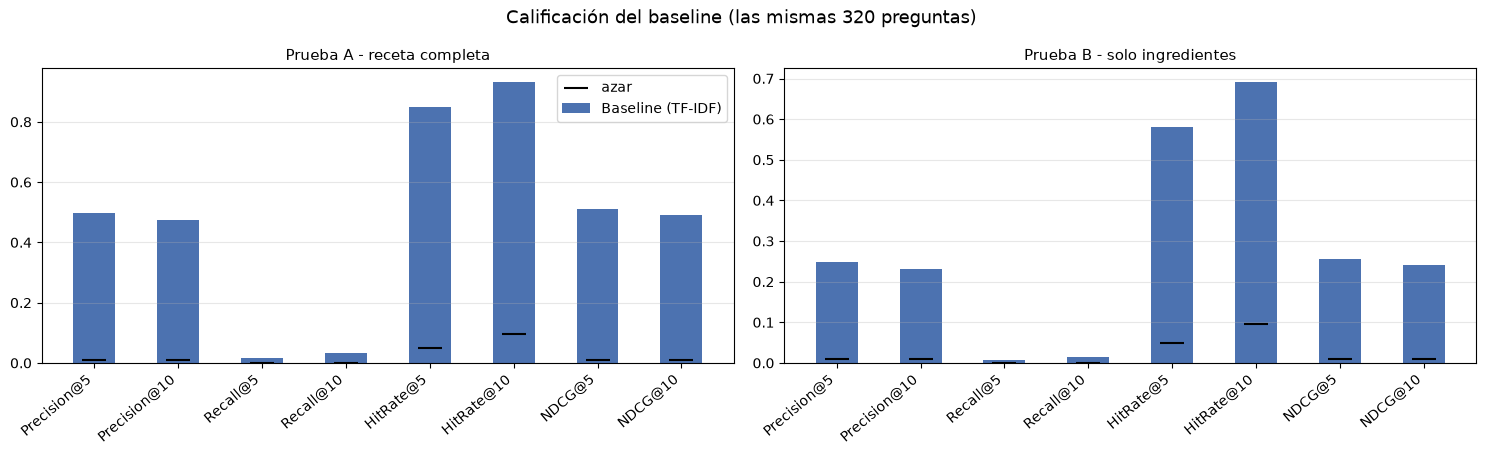

In [ ]:
# Gráfica: nota del baseline (barras azules) contra recomendar al azar (rayas negras), para cada métrica.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))     # dos paneles: Prueba A (izquierda) y Prueba B (derecha)
ancho = 0.5                                           # ancho de cada barra
x = np.arange(len(ORDER))                             # posición de cada métrica en el eje horizontal
for ax, p in zip(axes, ("A", "B")):
    t = tabla_baseline[p]
    ax.bar(x, t.loc["Baseline (TF-IDF)"], ancho, label="Baseline (TF-IDF)", color="#4C72B0")
    ax.scatter(x, t.loc["Azar (referencia)"], color="k", marker="_", s=300, label="azar", zorder=3)
    ax.set_xticks(x, ORDER, rotation=40, ha="right")
    ax.set_title(PROTOCOL_NAMES[p], fontsize=11)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend()
fig.suptitle(f"Calificación del baseline (las mismas {N_QUERIES} preguntas)", fontsize=13)
fig.tight_layout()
plt.show()                                                          # ...y la mostramos


**Cómo leer estos resultados** (con los números de esta corrida):

**Prueba A: "me gustó esta receta, ¿qué más hay parecido?"**

* `Precision@10 = 0.474`: de cada 10 recetas que recomienda, **casi 5** son del mismo tipo de plato.
* `HitRate@10 = 0.928`: en el **93 %** de las preguntas, al menos una de las 10 recomendaciones es del mismo tipo de plato.
* `NDCG@10 = 0.492`: los aciertos quedan en lugares razonablemente altos de la lista.
* Recomendar al azar da `Precision@10 = 0.0105`: el baseline es **más de 40 veces mejor** que el azar.

**Prueba B: "tengo estos ingredientes, ¿qué cocino?"**

* `Precision@10 = 0.231`: más o menos **2 de cada 10** recomendaciones son del tipo correcto.
* `HitRate@10 = 0.691`: en **7 de cada 10** preguntas hay al menos un acierto en el Top-10.
* Es más baja que la A porque aquí el modelo **no ve el nombre del plato**, solo ingredientes. Aun así es **unas 20 veces mejor** que el azar.

**Sobre `Recall`:** sale siempre muy chico (0.03 o menos) y **es normal**: hay cientos de recetas que cuentan como acierto
(por ejemplo, 865 sopas) y solo mostramos 10. No lo uses para comparar contra otros números fuera de este notebook.

**Conclusión de esta sección:** el baseline funciona (le gana por mucho al azar), pero **tiene margen para mejorar**, sobre todo en la Prueba B.
Estas son las notas que el Modelo 2 (embeddings) tiene que superar.

### 1.11.7 ¿En qué tipos de plato le va mejor y peor?

Un promedio puede esconder cosas. Aquí vemos el NDCG@10 del baseline por tipo de plato: los **5 más difíciles** y los **5 más fáciles** (según la Prueba A).


In [20]:
# NDCG@10 del baseline en cada tipo de plato, para las dos pruebas (qué tipos le salen bien y cuáles mal)
por_tipo = pd.concat(
    [resultados_baseline[p].groupby("group")["NDCG@10"].mean().rename(f"Baseline {p}") for p in ("A", "B")],
    axis=1,
).sort_values("Baseline A")        # de peor a mejor en la prueba A

print("Los 5 tipos de plato MÁS DIFÍCILES para el baseline:")
display(por_tipo.head(5).round(3))
print("Los 5 tipos de plato MÁS FÁCILES para el baseline:")
display(por_tipo.tail(5).round(3))


Los 5 tipos de plato MÁS DIFÍCILES para el baseline:


,Baseline A,Baseline B
group,,
brochetas,0.214,0.079
tostadas,0.228,0.088
cheesecake,0.302,0.085
burritos,0.343,0.077
quesadillas,0.347,0.121


Los 5 tipos de plato MÁS FÁCILES para el baseline:


,Baseline A,Baseline B
group,,
galletas,0.648,0.241
ceviche,0.658,0.286
gelatina,0.690,0.573
coctel_alcohol,0.719,0.293
croquetas,0.772,0.410


**Qué nos dice:** al baseline le va muy bien con platos que casi siempre llevan la **palabra del plato** en el nombre y en los ingredientes
(croquetas, gelatina, cócteles) y mucho peor con tipos como brochetas o tostadas, donde el nombre dice poco y los ingredientes se parecen a los de otros platos.
Esto es justo lo que el notebook 04 intenta mejorar.


## 1.12 Resumen del baseline

```text
recetas_modelo.csv
    ↓
recipe_text  (nombre + ingredientes base + etiquetas + país)
    ↓
TF-IDF       (cada palabra recibe un puntaje: alto si es rara, bajo si es común)
    ↓
una fila de números por receta
    ↓
similitud coseno  (0 = nada que ver, 1 = idénticas)
    ↓
las N recetas más parecidas  (+ filtros opcionales: rápido, vegetariano...)
    ↓
calificación con 320 preguntas de prueba (métricas)
```

| Notas del baseline | Prueba A (receta completa) | Prueba B (solo ingredientes) | Azar |
| --- | --- | --- | --- |
| Precision@10 | 0.474 | 0.231 | 0.011 |
| HitRate@10 | 0.928 | 0.691 | 0.095 |
| NDCG@10 | 0.492 | 0.241 | 0.011 |

**Qué sigue:** el notebook 04 construye el modelo de embeddings. El notebook 05 los compara con las mismas preguntas.
